# v2 — Notebook 01 · Exploratory Data Analysis (EU monthly trade)

**Author's note / how to use this notebook.** This is the *first* step of the v2 pipeline.
Its job is **not** to detect anomalies yet — it is to **understand the data** so every later
choice (cleaning, transforms, models) is *justified by something we actually saw*.

### The dataset in one line
Each **EU country's monthly trade with the rest of the world**, in **€ millions**, from
Jan 2002 to Apr 2026. Columns are named `CC_EXP` / `CC_IMP` (country code + flow). Full
meanings are in `v2/GLOSSARY.md`.

> ⚠️ This is **v2** (international trade). It is *not* v1 (the Jena climate sensors). Same
> machinery, different domain.

### Where EDA sits in the pipeline
```
  ┌────────┐   ┌────────────┐   ┌───────────┐   ┌──────────┐   ┌────────────┐
  │  DATA  │ → │  01 · EDA  │ → │ 02 Prep   │ → │ 03 Analy │ → │ 04 Anomaly │ → ...
  │  (CSV) │   │ (we are    │   │  -rocess  │   │  -sis    │   │  detection │
  └────────┘   │   here)    │   └───────────┘   └──────────┘   └────────────┘
               └────────────┘
   understand  ───────────────►  decisions made here flow into every later step
```

### How to read this notebook
Each section has the same shape:
1. **What** we're checking · **Why** it matters · **How to read** the chart.
2. The code (commented line-by-line).
3. A short takeaway → the **decision** it hands to the next step.

The seven questions we answer: *What is this? Is it clean? Is it growing? Is it seasonal?
Where are the real shocks? Do countries move together? So what?*

## Step 0 · Setup — load the data

**What:** import our tools and load the CSV into a pandas `DataFrame` with a proper
**datetime index** (sorted in time).
**Why:** a time series *must* be time-sorted with a real date index, or rolling windows,
seasonality and plots are all wrong.
**Libraries:** `pandas` (tables), `numpy` (maths), `matplotlib` (plots),
`statsmodels.STL` (trend/seasonal decomposition).

In [1]:
# Quiet, reproducible setup -------------------------------------------------
import warnings; warnings.filterwarnings("ignore")   # hide noisy library warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL            # Seasonal-Trend decomposition

plt.rcParams["figure.dpi"] = 110                     # crisper inline charts

def find_csv(name="eu_trade_monthly.csv"):
    # Locate data/<name> by walking up from the current folder, so the
    # notebook runs from any directory (root, v2/, or notebooks/).
    here = Path.cwd()
    for base in [here, *here.parents]:
        hit = base / "data" / name
        if hit.exists():
            return hit
    raise FileNotFoundError(name)

CSV = find_csv()
# index_col='month' -> use the month column as the row index
# parse_dates=True  -> read it as real timestamps, not strings
df = pd.read_csv(CSV, index_col="month", parse_dates=True).sort_index()

# Convenient column groups, reused throughout the notebook
EXP = [c for c in df.columns if c.endswith("_EXP")]   # 27 export columns
IMP = [c for c in df.columns if c.endswith("_IMP")]   # 27 import columns
print("Loaded:", CSV)
print("Shape :", df.shape, "(rows = months, columns = country-flows)")

Loaded: /home/saizer/Documents/Msc_project/code/data/eu_trade_monthly.csv
Shape : (292, 54) (rows = months, columns = country-flows)


## Step 1 · Document the data — *what is this?*

**What:** print the basic facts — time span, frequency, countries, units.
**Why:** you can't analyse what you can't describe. The most important fact is the **unit**:
`DE_EXP = 50330` means **€50.33 billion**, not 50,330 euros. Misreading units ruins everything
downstream.
**How to read:** the table at the end is the raw data — one row per month, a few example
country columns.

In [2]:
print("Time range :", df.index.min().date(), "->", df.index.max().date())
print("Frequency  :", pd.infer_freq(df.index), " (MS = month-start)")
print("Months     :", len(df))
countries = sorted({c.split('_')[0] for c in df.columns})
print("Countries  :", len(countries))
print("            ", countries)
print("Columns    :", df.shape[1], "= 27 countries x {EXP, IMP}")
print()
print("UNIT: trade value in MILLIONS of euro.")
print("e.g. DE_EXP = 50330  ->  Germany exported EUR 50.33 BILLION that month.")
# .head() shows the first 5 rows for a readable subset of columns
df[["DE_EXP", "DE_IMP", "FR_EXP", "IT_EXP", "NL_EXP"]].head()

Time range : 2002-01-01 -> 2026-04-01
Frequency  : MS  (MS = month-start)
Months     : 292
Countries  : 27
             ['AT', 'BE', 'BG', 'CY', 'CZ', 'DE', 'DK', 'EE', 'EL', 'ES', 'FI', 'FR', 'HR', 'HU', 'IE', 'IT', 'LT', 'LU', 'LV', 'MT', 'NL', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK']
Columns    : 54 = 27 countries x {EXP, IMP}

UNIT: trade value in MILLIONS of euro.
e.g. DE_EXP = 50330  ->  Germany exported EUR 50.33 BILLION that month.


,DE_EXP,DE_IMP,FR_EXP,IT_EXP,NL_EXP
month,,,,,
2002-01-01,50329.9,39805.6,27621.0,19882.3,20425.1
2002-02-01,51817.1,41260.8,28188.1,21591.6,20350.8
2002-03-01,54554.5,42311.5,30888.0,24075.1,22842.9
2002-04-01,56023.3,46009.5,30974.3,21285.5,20907.8
2002-05-01,50470.3,40064.3,28712.2,24174.8,21606.5


## Step 2 · Data quality — *is it clean?*

**What:** three checks that catch the things which silently break models:
missing cells, gaps in the monthly calendar, and impossible (≤ 0) values.
**Why:** a missing month punches a hole in every rolling window; a zero/negative trade value
would be a data error (you can't export −€5 bn). Clean data here = little cleaning later.
**How to read:** we want **all three numbers to be 0**.

In [3]:
missing_cells = int(df.isna().sum().sum())            # NaNs anywhere?
# Build the *complete* set of months and see which (if any) are absent from our index
full_calendar = pd.date_range(df.index.min(), df.index.max(), freq="MS")
missing_months = len(full_calendar.difference(df.index))
nonpositive = int((df <= 0).sum().sum())              # values that should be impossible

print(f"Missing cells   : {missing_cells}")
print(f"Missing months  : {missing_months}")
print(f"Non-positive    : {nonpositive}")
print(f"\nValue range (EUR m): {df.min().min():.1f}  ..  {df.max().max():.1f}")
print("=> All checks clean -> preprocessing will be minimal.")

Missing cells   : 0
Missing months  : 0
Non-positive    : 0

Value range (EUR m): 20.9  ..  151793.1
=> All checks clean -> preprocessing will be minimal.


### Step 2b · Distribution & scale — *why we'll log-transform*

**What:** histogram of *all* trade values, raw vs `log10`.
**Why:** trade values span a huge range (tiny Malta ↔ huge Germany; 2002 ↔ 2026). On a raw
scale a few giant numbers dominate; on a **log scale** the spread becomes roughly symmetric.
This is the visual justification for a **log transform** before anomaly detection.
**How to read:** left = heavily skewed (long right tail). Right = log makes it well-behaved.

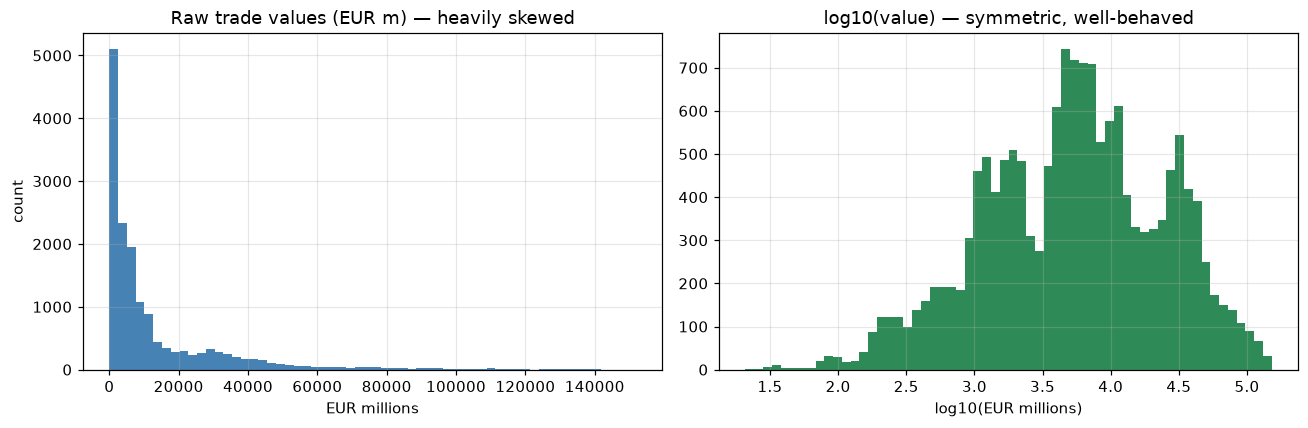

Skew collapses under log -> log-transform is the right call for modelling.


In [4]:
vals = df.values.flatten()
vals = vals[vals > 0]                                 # logs need positive numbers

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(vals, bins=60, color="steelblue")
ax[0].set_title("Raw trade values (EUR m) — heavily skewed")
ax[0].set_xlabel("EUR millions"); ax[0].set_ylabel("count")

ax[1].hist(np.log10(vals), bins=60, color="seagreen")
ax[1].set_title("log10(value) — symmetric, well-behaved")
ax[1].set_xlabel("log10(EUR millions)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("Skew collapses under log -> log-transform is the right call for modelling.")

## Step 3 · Trend — *is EU trade growing?*

**What:** sum all 27 countries into **total EU exports & imports**, plot over time, and shade
the **trade balance** (exports − imports) between them.
**Why:** the long-term direction shapes the whole analysis. If 2026 values are ~3× the 2008
values, an anomaly detector tuned to recent data will *miss* the 2008 crash unless we remove
the trend (or log-transform).
**How to read:** two rising lines = growth. The shaded gap = surplus (green, exports above
imports) vs deficit (red).

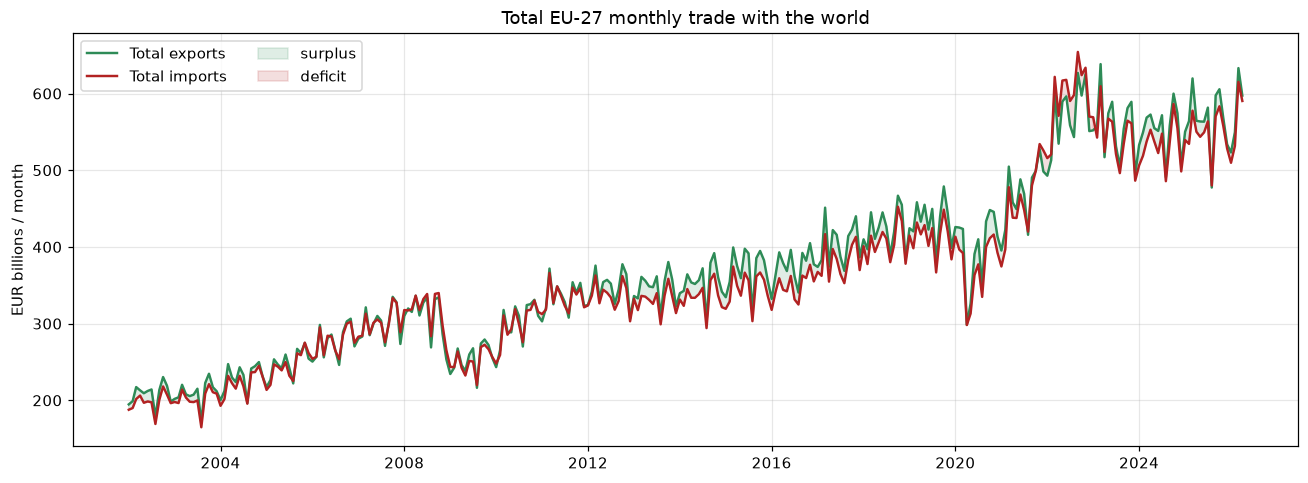

Exports grew 3.1x over the period — roughly exponential.


In [5]:
total_exp = df[EXP].sum(axis=1)
total_imp = df[IMP].sum(axis=1)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(total_exp.index, total_exp/1000, label="Total exports", color="seagreen", lw=1.6)
ax.plot(total_imp.index, total_imp/1000, label="Total imports", color="firebrick", lw=1.6)
# shade the balance: green where surplus, red where deficit
ax.fill_between(total_exp.index, total_exp/1000, total_imp/1000,
                where=(total_exp >= total_imp), color="seagreen", alpha=.15, label="surplus")
ax.fill_between(total_exp.index, total_exp/1000, total_imp/1000,
                where=(total_exp <  total_imp), color="firebrick", alpha=.15, label="deficit")
ax.set_title("Total EU-27 monthly trade with the world")
ax.set_ylabel("EUR billions / month"); ax.legend(ncol=2); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"Exports grew {total_exp.iloc[-1]/total_exp.iloc[0]:.1f}x over the period — roughly exponential.")

### Step 3b · Who are the big traders?

**What:** average **total trade** (exports + imports) per country, ranked.
**Why:** tells us which channels carry most of the signal — Germany/Netherlands/France
dominate, small states (Malta, Cyprus) are tiny. Useful when we later pick example countries.
**How to read:** longer bar = bigger trading nation.

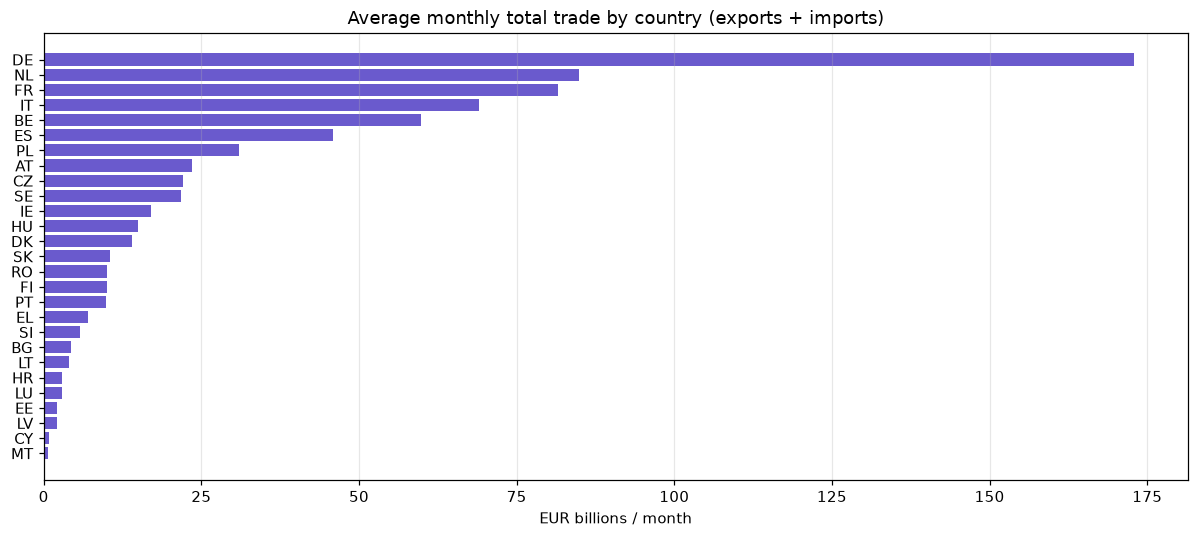

In [6]:
avg_total = (df[EXP].mean().values + df[IMP].mean().values)   # per-country avg EXP+IMP
rank = pd.Series(avg_total, index=[c[:2] for c in EXP]).sort_values()

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(rank.index, rank.values/1000, color="slateblue")
ax.set_title("Average monthly total trade by country (exports + imports)")
ax.set_xlabel("EUR billions / month"); ax.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()

## Step 3c · Country focus — France & Belgium (and their *losses*)

**Note on this dataset:** values are each country's trade with the **whole world**, not bilateral
France↔Belgium trade. So below we compare **France** and **Belgium** side by side (deliberately
*not* Germany) — their exports, imports, trade **balance**, and the **losses** during the crises.

**What:**
- *Top row* — exports vs imports over time, with the gap shaded.
- *Bottom row* — the **trade balance** (`exports − imports`). Below zero (red) = a **deficit**
  (the country buys more than it sells — a net "loss"); above zero (green) = a surplus.

**Why:** showing two different mid/large economies proves the patterns generalise beyond Germany.
France typically runs a **deficit**, Belgium a **surplus** — a nice contrast.
**How to read:** red shading in the bottom panels = months of trade *loss* (deficit).

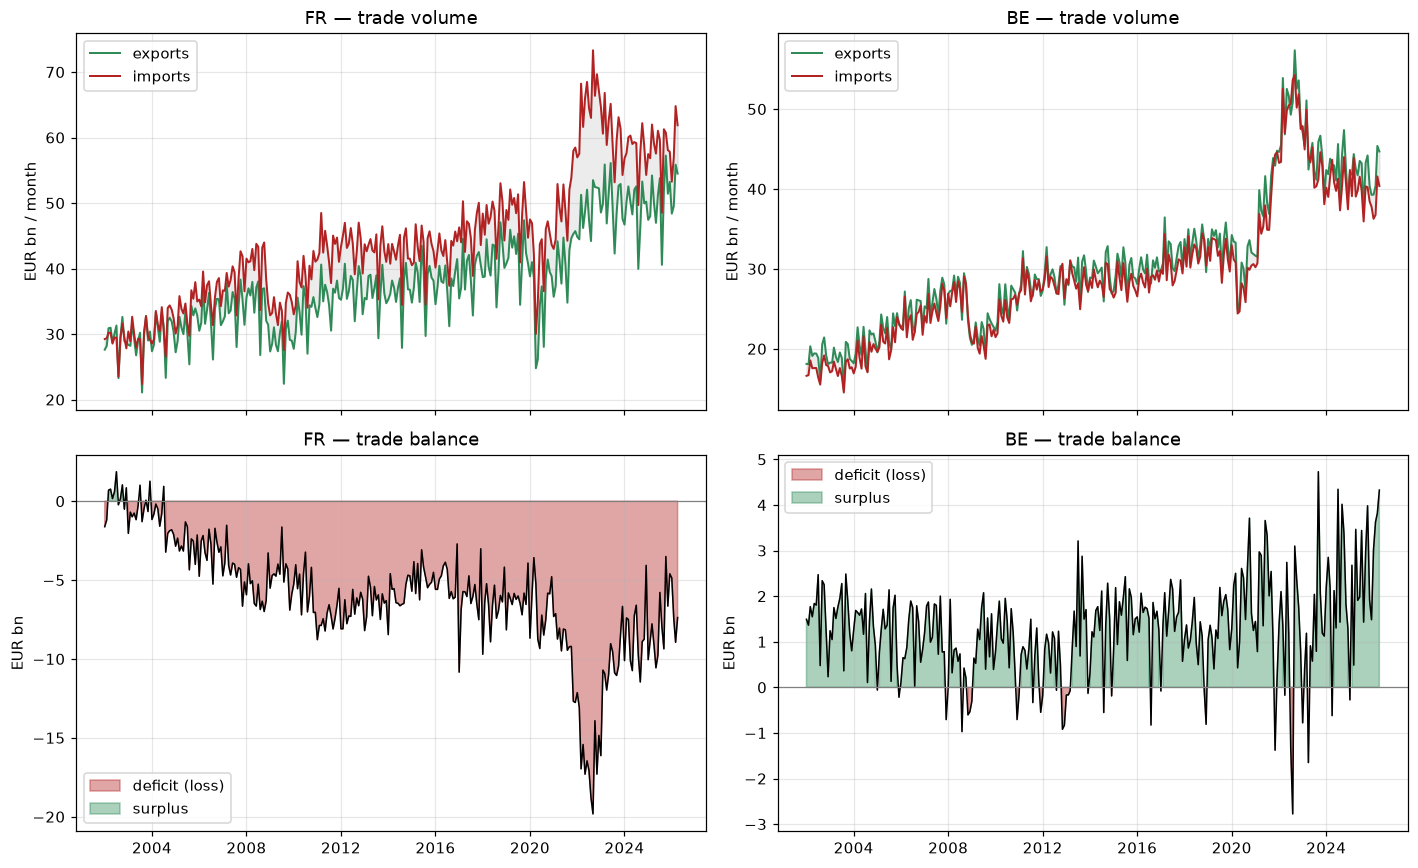

In [7]:
focus = ["FR", "BE"]                                  # France & Belgium (not Germany)
fig, ax = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

for col, cc in enumerate(focus):
    e = df[f"{cc}_EXP"]/1000                          # exports, EUR bn
    i = df[f"{cc}_IMP"]/1000                          # imports, EUR bn
    bal = e - i                                       # trade balance (+surplus / -deficit)

    # top: volume (exports vs imports)
    ax[0, col].plot(e.index, e, color="seagreen",  lw=1.3, label="exports")
    ax[0, col].plot(i.index, i, color="firebrick", lw=1.3, label="imports")
    ax[0, col].fill_between(e.index, e, i, color="grey", alpha=.15)
    ax[0, col].set_title(f"{cc} — trade volume"); ax[0, col].set_ylabel("EUR bn / month")
    ax[0, col].legend(); ax[0, col].grid(alpha=.3)

    # bottom: balance, red where in deficit ("loss")
    ax[1, col].plot(bal.index, bal, color="black", lw=1)
    ax[1, col].fill_between(bal.index, bal, 0, where=(bal < 0), color="firebrick", alpha=.4, label="deficit (loss)")
    ax[1, col].fill_between(bal.index, bal, 0, where=(bal >= 0), color="seagreen", alpha=.4, label="surplus")
    ax[1, col].axhline(0, color="grey", lw=.8)
    ax[1, col].set_title(f"{cc} — trade balance"); ax[1, col].set_ylabel("EUR bn"); ax[1, col].legend(); ax[1, col].grid(alpha=.3)

plt.tight_layout(); plt.show()

### Step 3c (cont.) · Quantifying the *loss* during each crisis

**What:** for France & Belgium, measure how much **export value was lost** at the bottom of the
2008 and COVID shocks (peak → trough), in both **% and € billions**.
**How to read:** a bigger negative number = a deeper trade loss that month.

country crisis           % drop   EUR bn lost
---------------------------------------------
FR      2008 crisis      -26.1%        -9.6
FR      COVID-19         -35.8%       -13.8
BE      2008 crisis      -27.5%        -7.8
BE      COVID-19         -25.4%        -8.5


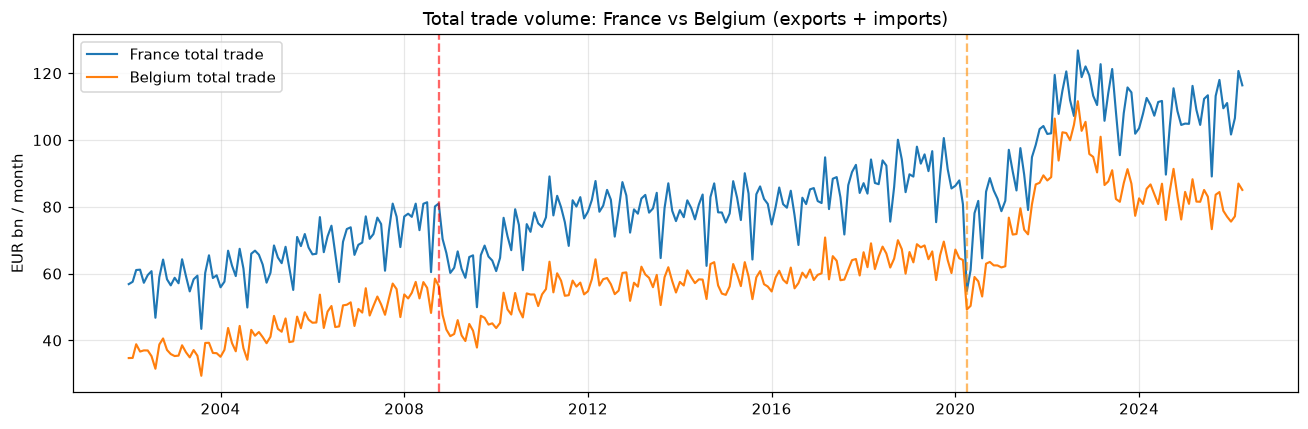

In [8]:
def crisis_loss(series, peak, trough):
    p, t = series.loc[peak], series.loc[trough]
    return (t - p) / p * 100, (t - p) / 1000          # (% change, EUR bn change)

print(f"{'country':8s}{'crisis':14s}{'% drop':>9s}{'EUR bn lost':>14s}")
print("-" * 45)
for cc in focus:
    for label, peak, tr in [("2008 crisis", "2008-10-01", "2009-01-01"),
                            ("COVID-19",   "2020-03-01", "2020-04-01")]:
        pct, eur = crisis_loss(df[f"{cc}_EXP"], peak, tr)
        print(f"{cc:8s}{label:14s}{pct:>8.1f}%{eur:>12.1f}")

# Also: a simple total-trade-volume comparison of the two countries
tot_fr = (df["FR_EXP"] + df["FR_IMP"]) / 1000
tot_be = (df["BE_EXP"] + df["BE_IMP"]) / 1000
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(tot_fr.index, tot_fr, label="France total trade", lw=1.4)
ax.plot(tot_be.index, tot_be, label="Belgium total trade", lw=1.4)
for x, c in [("2008-10-01", "red"), ("2020-04-01", "darkorange")]:
    ax.axvline(pd.Timestamp(x), color=c, ls="--", alpha=.6)
ax.set_title("Total trade volume: France vs Belgium (exports + imports)")
ax.set_ylabel("EUR bn / month"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Step 4 · Seasonality — *is there a yearly cycle?*

**What:** decompose Germany's exports with **STL** into three parts and also show a
**boxplot by calendar month**.
**Why:** seasonality is *normal* repeating behaviour (factory holidays in summer/December). If
we don't account for it, a detector flags every December as "abnormal". STL separates it out.
**How to read STL (3 panels):**
- **Trend** = the slow underlying level.
- **Seasonal** = the repeating yearly wave.
- **Residual** = what's left → *this is where real anomalies live.*

`STL(..., period=12)` because 12 months = one yearly cycle.

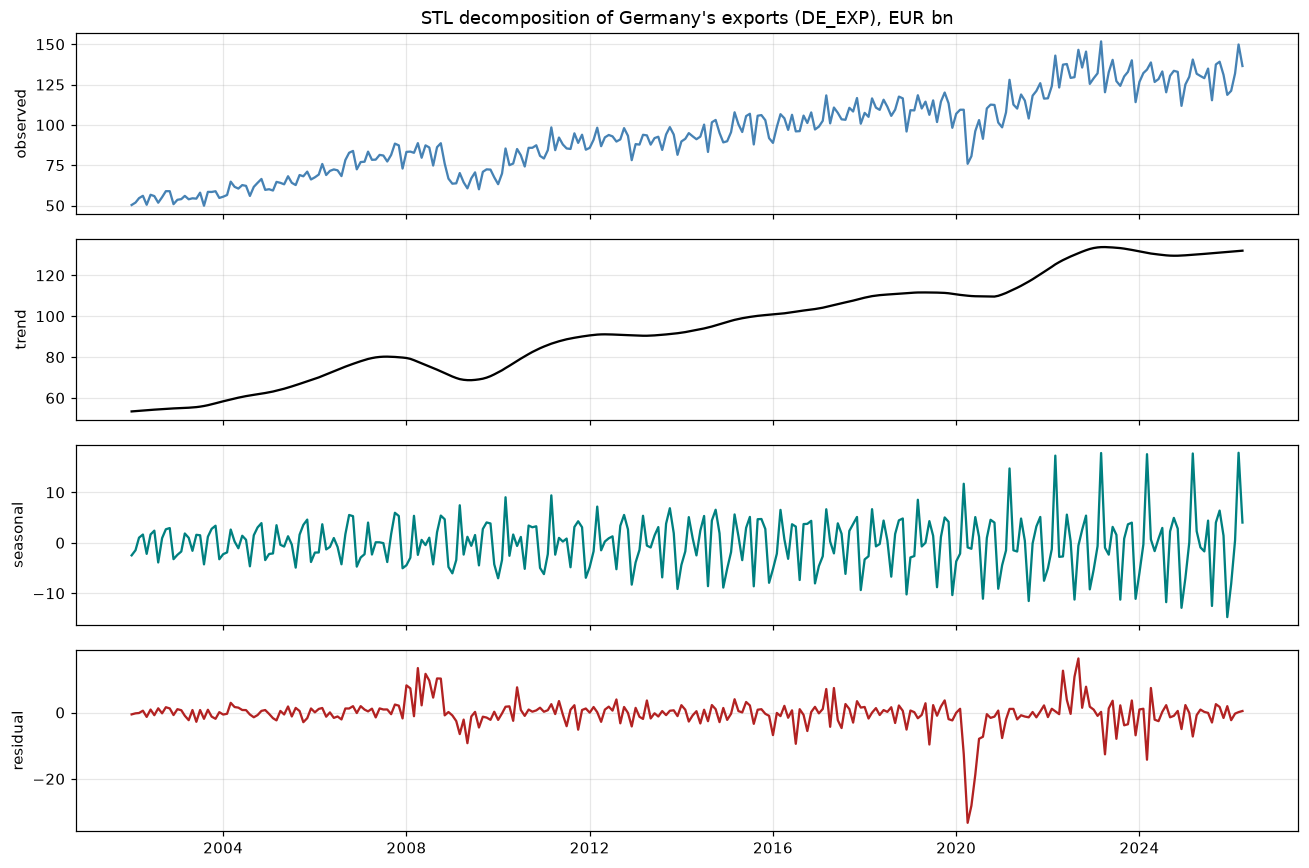

Yearly seasonal swing ~ EUR 32.6 bn. The 2008 & 2020 dips show up clearly in the RESIDUAL.


In [9]:
s = df["DE_EXP"]
stl = STL(s, period=12, robust=True).fit()            # robust = down-weight outliers

fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
ax[0].plot(s.index, s/1000, color="steelblue");        ax[0].set_ylabel("observed")
ax[1].plot(stl.trend.index, stl.trend/1000, color="black");    ax[1].set_ylabel("trend")
ax[2].plot(stl.seasonal.index, stl.seasonal/1000, color="teal"); ax[2].set_ylabel("seasonal")
ax[3].plot(stl.resid.index, stl.resid/1000, color="firebrick");  ax[3].set_ylabel("residual")
ax[0].set_title("STL decomposition of Germany's exports (DE_EXP), EUR bn")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

amp = (stl.seasonal.max() - stl.seasonal.min())/1000
print(f"Yearly seasonal swing ~ EUR {amp:.1f} bn. The 2008 & 2020 dips show up clearly in the RESIDUAL.")

### Step 4b · The seasonal shape, month by month

**How to read:** each box is one calendar month across all years. Lower boxes (e.g. summer,
December) are the regular dips. Consistent box positions = a strong, reliable yearly pattern.

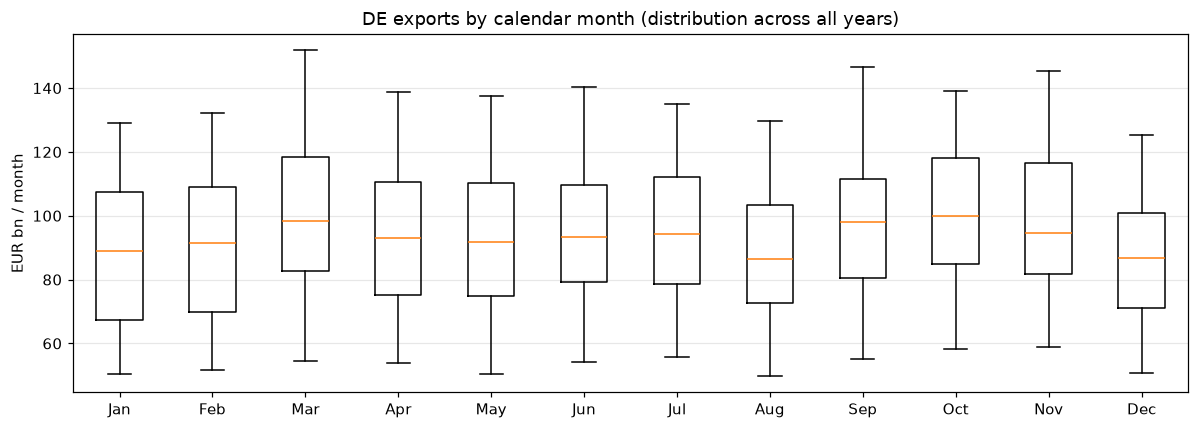

In [10]:
# group export values by calendar month (1..12) and box-plot each group
by_m = [s[s.index.month == m].values/1000 for m in range(1, 13)]
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(by_m)                                      # one box per calendar month
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("DE exports by calendar month (distribution across all years)")
ax.set_ylabel("EUR bn / month"); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

## Step 5 · The shocks — *where are the real anomalies?*

**What:** measure and mark the two known crises (2008, COVID), then show that the COVID dip
hit **many countries at once**.
**Why:** these are **real, datable anomalies** — gold for v2. Later we can prove a detector
catches a *genuine event*, not just a synthetic spike we injected (a strength v1 lacked).
**How to read:** dashed lines mark the crisis months; the second chart normalises several
countries to 100 at Jan-2020 so their **synchronised collapse** is visible on one scale.

2008 crisis : DE_EXP 88,632 -> 63,543 EUR m  (-28.3%)
COVID-19    : DE_EXP 109,406 -> 75,861 EUR m  (-30.7%)


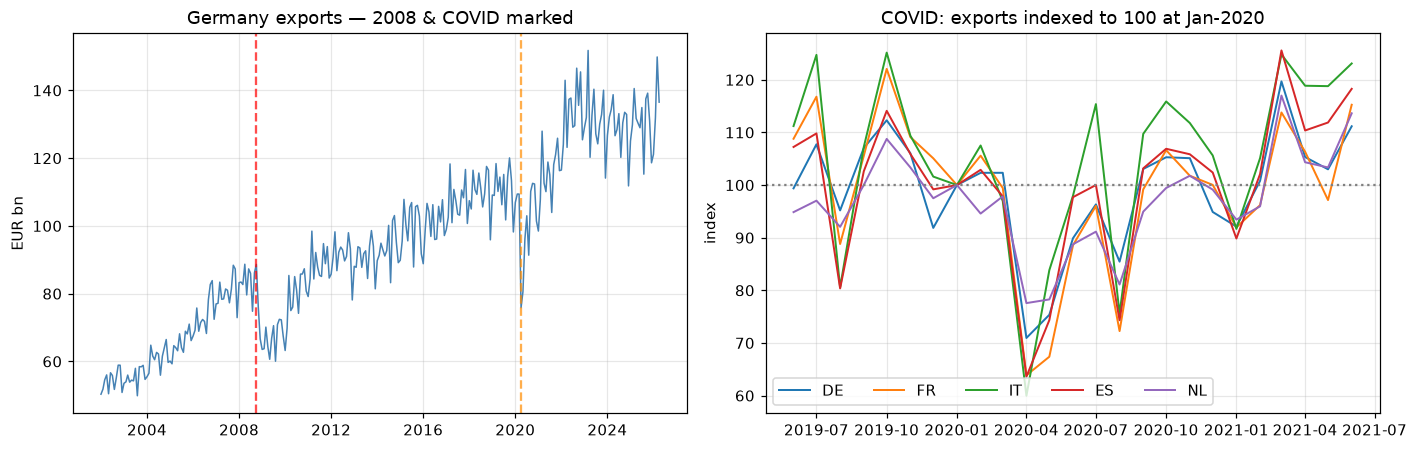

All countries dip together in Apr-2020 -> a SHARED shock (motivates multi-country reasoning).


In [11]:
def drop(series, peak, trough):
    p, t = series.loc[peak], series.loc[trough]
    return p, t, (t - p)/p*100

for label, peak, tr in [("2008 crisis","2008-10-01","2009-01-01"),
                        ("COVID-19","2020-03-01","2020-04-01")]:
    p, t, d = drop(df["DE_EXP"], peak, tr)
    print(f"{label:12s}: DE_EXP {p:,.0f} -> {t:,.0f} EUR m  ({d:+.1f}%)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
# (a) full Germany series with crisis markers
ax[0].plot(df.index, df["DE_EXP"]/1000, color="steelblue", lw=1)
for x, c in [("2008-10-01","red"), ("2020-04-01","darkorange")]:
    ax[0].axvline(pd.Timestamp(x), color=c, ls="--", alpha=.7)
ax[0].set_title("Germany exports — 2008 & COVID marked"); ax[0].set_ylabel("EUR bn"); ax[0].grid(alpha=.3)

# (b) several countries, indexed to 100 at Jan-2020, zoomed on 2019-2021
win = df.loc["2019-06":"2021-06", ["DE_EXP","FR_EXP","IT_EXP","ES_EXP","NL_EXP"]]
norm = win / win.loc["2020-01-01"] * 100             # 100 = pre-COVID baseline
for col in norm.columns:
    ax[1].plot(norm.index, norm[col], label=col[:2], lw=1.3)
ax[1].axhline(100, color="grey", ls=":")
ax[1].set_title("COVID: exports indexed to 100 at Jan-2020"); ax[1].set_ylabel("index"); ax[1].legend(ncol=5); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("All countries dip together in Apr-2020 -> a SHARED shock (motivates multi-country reasoning).")

## Step 6 · Correlations — *do countries move together?* (multi-sensor angle)

**What:** correlation heatmap across countries' export **growth**, plus an exports-vs-imports
scatter for one country.
**Why two subtleties:**
1. We correlate **month-over-month growth**, *not* raw values — otherwise everything looks
   correlated just because all countries trend upward (a *spurious* correlation). Growth strips
   the shared trend so we see *genuine* co-movement.
2. High co-movement justifies **multi-country reasoning**: if Spain & Italy fall together, it's
   likely a shared shock, not an Italy-specific issue.
**How to read:** greener = move together; the scatter shows exports and imports rise together
(a country that trades more, trades more both ways).

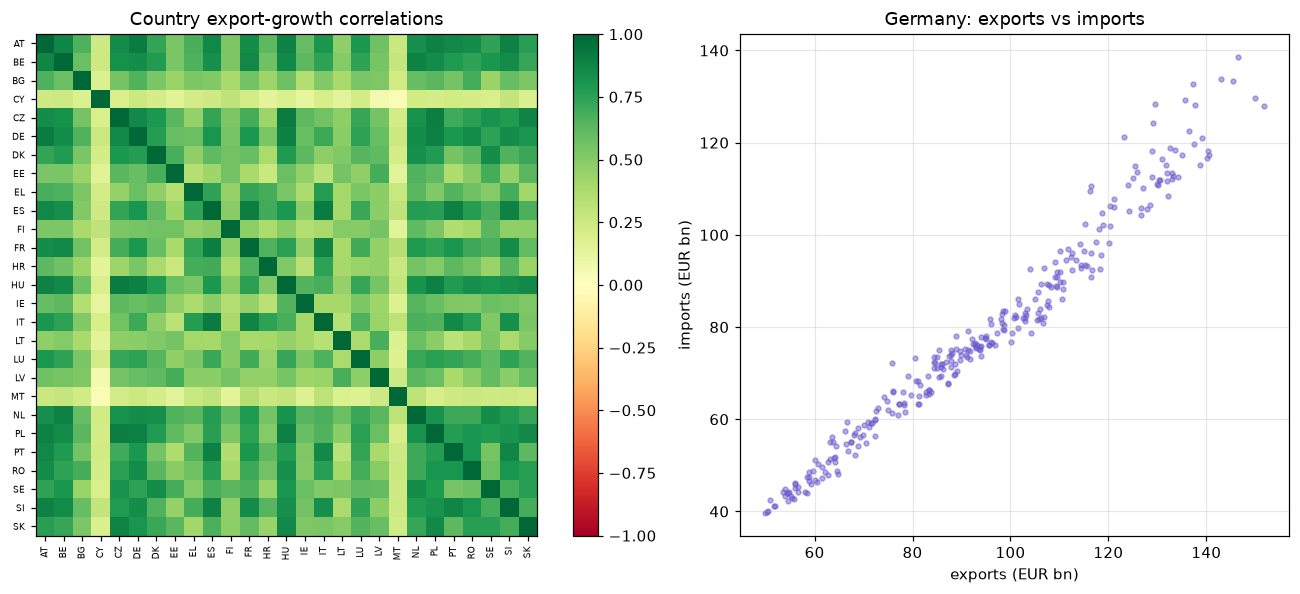

Most co-moving export pairs:
ES_EXP  IT_EXP    0.91
AT_EXP  DE_EXP    0.91
CZ_EXP  HU_EXP    0.91
        PL_EXP    0.91
ES_EXP  FR_EXP    0.90

Mean cross-country correlation: 0.57  (high => shared shocks).


In [12]:
growth = df[EXP].pct_change().dropna()                # monthly % change per country
corr = growth.corr()

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios":[1.3,1]})
im = ax[0].imshow(corr, cmap="RdYlGn", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(EXP))); ax[0].set_xticklabels([c[:2] for c in EXP], rotation=90, fontsize=6)
ax[0].set_yticks(range(len(EXP))); ax[0].set_yticklabels([c[:2] for c in EXP], fontsize=6)
ax[0].set_title("Country export-growth correlations")
fig.colorbar(im, ax=ax[0], fraction=.046)

ax[1].scatter(df["DE_EXP"]/1000, df["DE_IMP"]/1000, s=10, alpha=.5, color="slateblue")
ax[1].set_title("Germany: exports vs imports"); ax[1].set_xlabel("exports (EUR bn)"); ax[1].set_ylabel("imports (EUR bn)")
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

# strongest co-moving pairs (upper triangle only, no self-pairs)
pairs = corr.where(~np.eye(len(corr), dtype=bool)).stack()
pairs = pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)].sort_values(ascending=False)
print("Most co-moving export pairs:")
print(pairs.head(5).round(2).to_string())
print(f"\nMean cross-country correlation: {pairs.mean():.2f}  (high => shared shocks).")

## Step 7 · A peek ahead — turning the residual into an anomaly score

**What:** a *preview* of step 04. We take the STL **residual** of Germany's exports, convert it
to a **z-score** (how many standard deviations from normal), and flag |z| > 3.
**Why:** to show the EDA findings connect directly to anomaly detection — the crises we eyeballed
become the **largest residual z-scores**. This is not the final detector, just a sanity check.
**How to read:** red dots = flagged points. They should land on 2008 and 2020.

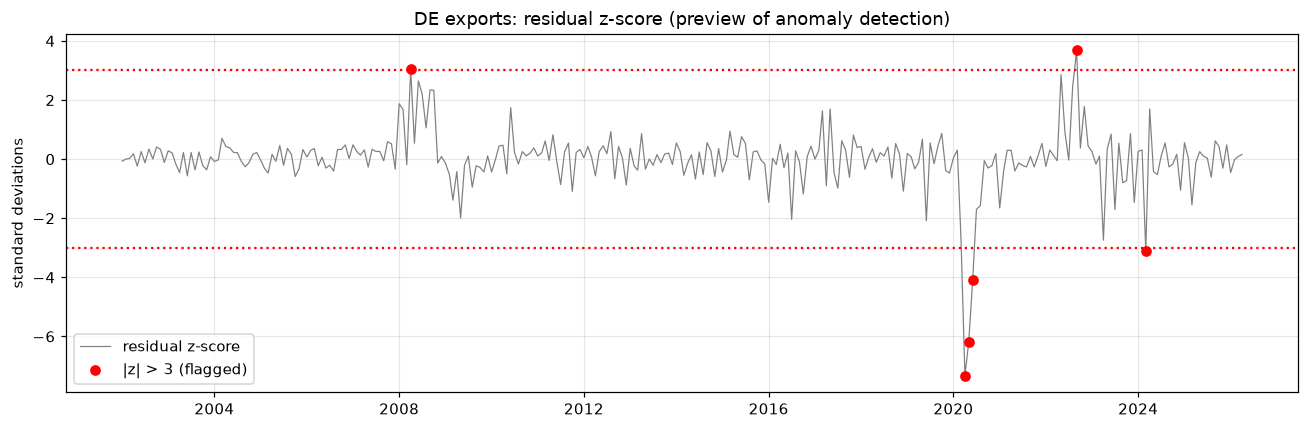

Flagged months: ['2008-04', '2020-04', '2020-05', '2020-06', '2022-09', '2024-03']


In [13]:
resid = stl.resid                                     # leftover after trend+season removed
z = (resid - resid.mean()) / resid.std()              # standardise
flag = z.abs() > 3                                    # simple 3-sigma rule

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(z.index, z, color="grey", lw=.8, label="residual z-score")
ax.scatter(z.index[flag], z[flag], color="red", zorder=5, label="|z| > 3 (flagged)")
ax.axhline(3, color="red", ls=":"); ax.axhline(-3, color="red", ls=":")
ax.set_title("DE exports: residual z-score (preview of anomaly detection)")
ax.set_ylabel("standard deviations"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("Flagged months:", [d.strftime("%Y-%m") for d in z.index[flag]])

## Step 8 · Findings — *so what?*

Every observation above becomes a **decision** for the next steps:

| What we saw | Decision it drives |
| --- | --- |
| 292×54, 0 missing, no gaps, all > 0 | **Minimal cleaning** in preprocessing |
| Values heavily skewed; ~3× growth | **Log-transform** before anomaly detection |
| Clear yearly cycle (summer/Dec dips) | **STL with period = 12** |
| 2008 ≈ −28%, COVID ≈ −30% | **Built-in ground-truth anomalies** for evaluation |
| Countries co-move (mean corr 0.57) | **Multi-country reasoning** is well-motivated |
| Residual z-score already flags the crises | Anomaly detection is **viable** on this data |

**The throughline:** nothing later in the pipeline is arbitrary — each choice traces back to
something we *saw* here. That is exactly what makes the methodology defensible.

**→ Next: Notebook 02 · Preprocess** — load + validate, derive `balance` (EXP−IMP) and `total`
(EXP+IMP), add the log-transform option, and keep the clean monthly index.